# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [5]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import platform
import warnings
warnings.filterwarnings('ignore')

# OS별 한글 폰트 설정 (Windows: 맑은 고딕 / Mac: AppleGothic / 그외(Colab 등): 나눔고딕)
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

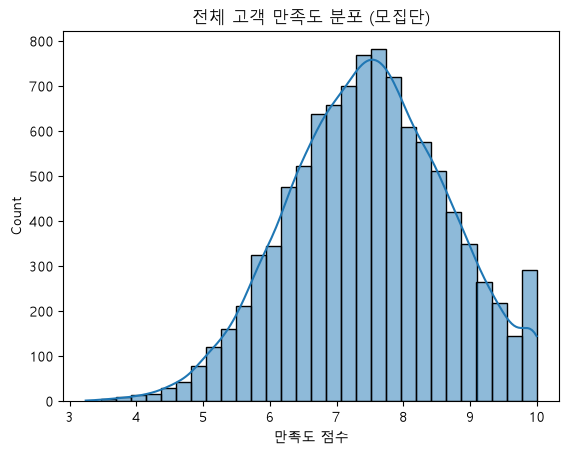

In [64]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})
np.random.seed()

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [61]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
# 여기에 코드를 작성해주세요.

pop_sample = np.random.choice(population, size=30, replace=False)
sample_mean = pop_sample.mean()

print(f'[Q1] 표본 평균: {sample_mean:.3f}')
print(f'[Q1] 모집단 평균: {np.mean(population):.2f}\n')


[Q1] 표본 평균: 7.671
[Q1] 모집단 평균: 7.48



In [69]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
# 여기에 코드를 작성해주세요.

means = []
for i in range(500):
    pop_sample = np.random.choice(population, size=30, replace=False)
    means.append(np.mean(pop_sample))

sample_means = np.mean(means)
standard_error = np.std(means, ddof=1)

print(f'[Q2] 표본 평균의 평균: {sample_means:.2f}')
print(f'[Q2] 표준 오차: {standard_error:.2f}')

[Q2] 표본 평균의 평균: 7.50
[Q2] 표준 오차: 0.22


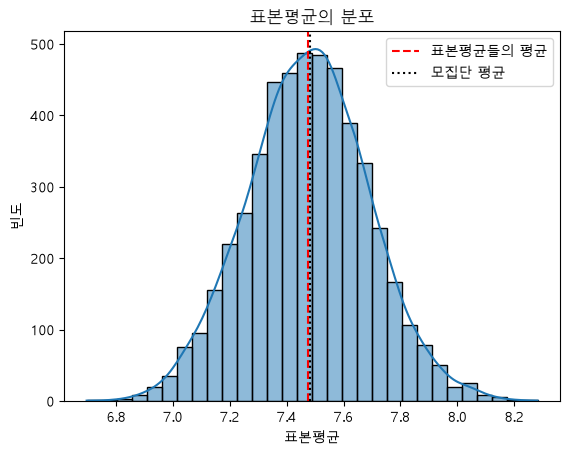

In [68]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
# 여기에 코드를 작성해주세요.

sns.histplot(means, bins=30, kde=True)
plt.axvline(sample_means, color='red', linestyle='--', label='표본평균들의 평균')
plt.axvline(np.mean(population), color='black', linestyle=':', label='모집단 평균')

plt.title("표본평균의 분포")
plt.xlabel("표본평균")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?

In [ ]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# [문제 1] 데이터를 어떻게 읽을까요?

# 1. 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 모집단 평균과 얼마나 비슷한가요?
#    → 표본 평균들은 모평균(약 7.5) 주변에 가장 많이 분포한다.
#      500개 표본 평균의 평균은 모평균과 거의 같았다.
#      반복 횟수가 많아질수록 표본 평균의 평균은 모평균에 더 가까워진다.

# 2. 표본을 1번 뽑았을 때와 500번 반복했을 때, 분포나 신뢰성에는 어떤 차이가 있나요?
#    → 표본을 1번만 뽑으면 그 평균이 모평균과 꽤 떨어진 값이 나오기도 한다.
#      500번 반복하면 표본 평균의 평균이 모평균과 거의 같아지고,
#      표본 평균들이 모평균을 중심으로 어떻게 퍼져 있는지 분포가 드러난다.
#      즉, 한 번의 결과만으로는 오차의 크기를 알 수 없지만,
#      반복하면 '표본 평균이 보통 어느 정도 범위에서 흔들리는지'를 알 수 있다.

# 3. 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 다르다면 그 이유는?
#    → 비슷하지만 완전히 같은 평균은 나오지 않는다.
#      무작위로 뽑히는 사람이 매번 달라서 생기는 '표본추출 오차(sampling error)' 때문이다.

# 4. 표본 평균들의 분포는 어떤 모양인가요? 정규분포처럼 보인다면 그 이유는?
#    → 모평균을 중심으로 좌우대칭인 종 모양으로, 정규분포와 비슷하다.
#      이는 '중심극한정리'로 설명된다. 표본 크기가 충분히 크면
#      표본 평균들의 분포는 정규분포에 가까워진다.

# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

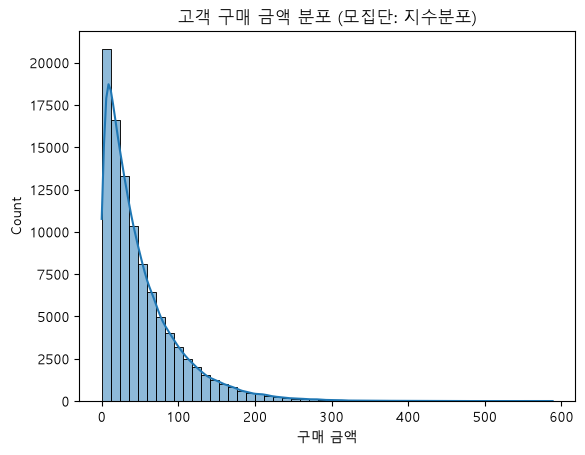

In [10]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [71]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때

# 여기에 코드를 작성해주세요.

np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포
np.random.seed()

means_5 = []
for _ in range(1000):
     # 1000번 반복
    pop_sample = np.random.choice(population, size=5, replace=False
)    # 매번 새로 5개 뽑고
    means_5.append(pop_sample.mean())
     # 그 평균을 저장

print(f'표본 평균들의 평균: {np.mean(means_5):.2f}')
print(f'모집단 평균      : {np.mean(population):.2f}')

표본 평균들의 평균: 50.74
모집단 평균      : 50.23


In [72]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100

# 여기에 코드를 작성해주세요.

np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 표본 크기 30
means_30 = []
for _ in range(1000):
    pop_sample = np.random.choice(population, size=30, replace=False)
    means_30.append(pop_sample.mean())

print(f'[n=30]  표본 평균들의 평균: {np.mean(means_30):.2f}')

# 표본 크기 100
means_100 = []
for _ in range(1000):
    pop_sample = np.random.choice(population, size=100, replace=False)
    means_100.append(pop_sample.mean())

print(f'[n=100] 표본 평균들의 평균: {np.mean(means_100):.2f}')
print(f'모집단 평균               : {np.mean(population):.2f}')

[n=30]  표본 평균들의 평균: 50.52
[n=100] 표본 평균들의 평균: 50.46
모집단 평균               : 50.23


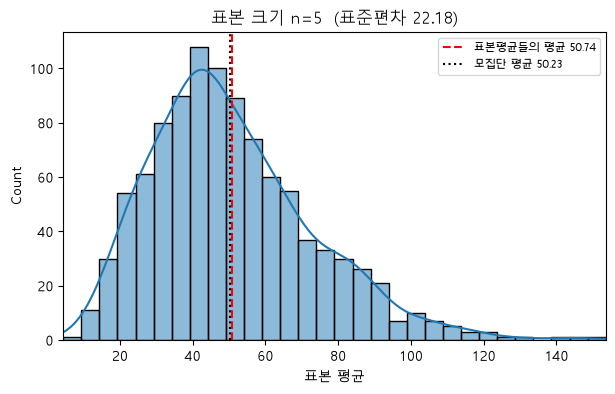

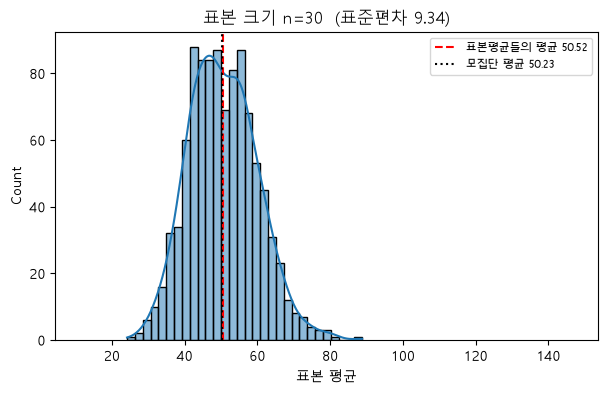

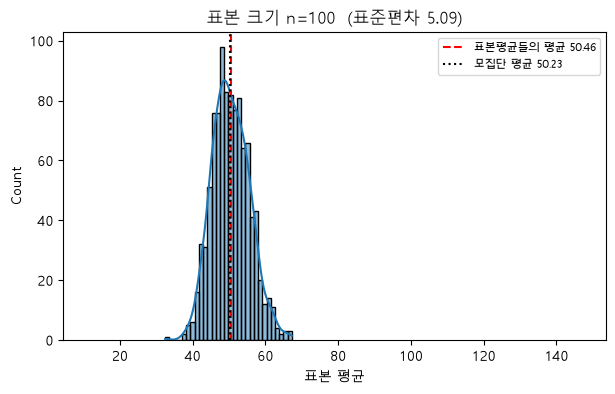

In [73]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

results = {5: means_5, 30: means_30, 100: means_100}

# 세 그래프의 x축 범위를 똑같이 맞춰서 퍼진 정도를 비교하기 위함
x_min = min(np.min(m) for m in results.values())
x_max = max(np.max(m) for m in results.values())

for n, means in results.items():
    plt.figure(figsize=(7, 4))                       # 그래프마다 새 figure
    sns.histplot(means, bins=30, kde=True)
    plt.axvline(np.mean(means), color='red', linestyle='--', label=f'표본평균들의 평균 {np.mean(means):.2f}')
    plt.axvline(np.mean(population), color='black', linestyle=':', label=f'모집단 평균 {np.mean(population):.2f}')
    plt.xlim(x_min, x_max)
    plt.title(f'표본 크기 n={n}  (표준편차 {np.std(means):.2f})')
    plt.xlabel('표본 평균')
    plt.legend(fontsize=8)
    plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?

In [74]:
# [문제 2]데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 1. 표본 크기가 작을 때(n=5) 평균들의 분포는 어떤 모양인가요?
#    → 모집단(지수분포)의 영향이 남아 있어, 오른쪽으로 꼬리가 길게 늘어진 비대칭 모양이다.

# 2. 표본 크기가 커질수록 평균 분포의 모양은 어떻게 변하나요?
#    → n=30, 100으로 커질수록 좌우대칭인 종 모양, 즉 정규분포에 가까워진다.
#      이때 분포의 중심은 계속 모평균(약 50) 근처에 있다.

# 3. 모집단은 비대칭인데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?
#    → 중심극한정리(CLT) 때문이다. 여러 값을 평균 내면 아주 큰 값과 작은 값이 서로 상쇄되어,
#      극단적인 평균은 드물고 모평균 근처의 평균이 많아진다.
#      표본 크기가 커질수록 이 상쇄 효과가 커져서 분포가 정규분포 모양이 된다.

# 4. 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?
#    → 모집단의 분포 모양과 상관없이, 표본 크기가 충분히 크면
#      '표본 평균들의 분포'는 정규분포에 가까워진다.
#      그래서 모집단이 정규분포가 아니어도 정규분포를 이용해 평균을 추론할 수 있다.

# 5. 표본 크기에 따라 분포의 넓이(흩어짐)는 어떻게 달라지나요?
#    → 표본 크기가 커질수록 분포가 좁아진다.
#      표본 평균들의 표준편차(표준오차)는 σ/√n이라서, 실험에서도
#      n=5일 때 약 22 → n=30일 때 약 9 → n=100일 때 약 5로 줄어들었다.

# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

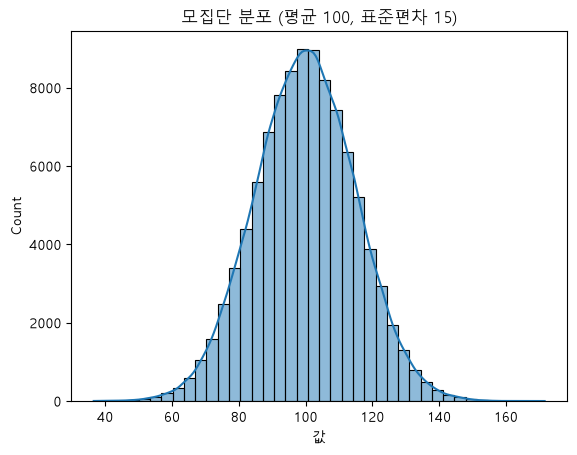

In [75]:
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)
np.random.seed()

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

In [ ]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

sample_sizes = [10, 30, 100, 500]
sim_se = []      # 표본 크기별 '표본 평균들의 표준편차' (= 실험적 표준오차)

for n in sample_sizes:
    means = []
    for _ in range(1000):                                              # 1000번 반복
        pop_sample = np.random.choice(population, size=n, replace=False)
        means.append(pop_sample.mean())
    sim_se.append(np.std(means))                                       #평균 1000개의 표준편차

# 표로 정리
df_se = pd.DataFrame({
    '표본 크기': sample_sizes,
    '실험적 표준오차': sim_se
})

df_se

,표본 크기,실험적 표준오차
0,10,4.583654
1,30,2.827487
2,100,1.548355
3,500,0.682270


,표본 크기,실험적 표준오차
0,10,4.769317
1,30,2.695949
2,100,1.526309
3,500,0.661793


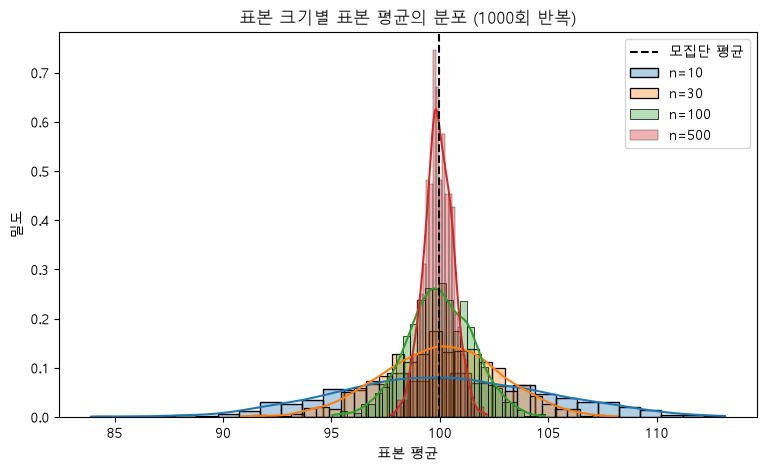

In [ ]:
# [문제 3] Q1(참고). 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

sample_sizes = [10, 30, 100, 500]
sim_se = []        # 표본 크기별 '표본 평균들의 표준편차' (= 실험적 표준오차)
all_means = {}     # 표본 크기별 표본 평균 1000개 저장 (히스토그램용)

for n in sample_sizes:
    means = []
    for _ in range(1000):
        pop_sample = np.random.choice(population, size=n, replace=False)
        means.append(pop_sample.mean())
    all_means[n] = means
    sim_se.append(np.std(means))

# 표로 정리
df_se = pd.DataFrame({'표본 크기': sample_sizes, '실험적 표준오차': sim_se})
display(df_se)

# 표본 크기별 표본 평균 분포 히스토그램 (겹쳐서, 투명도 적용)
plt.figure(figsize=(9, 5))
for n, means in all_means.items():
    sns.histplot(means, bins=30, stat='density', kde=True, alpha=0.35, label=f'n={n}')
plt.axvline(population.mean(), color='black', linestyle='--', label='모집단 평균')
plt.title('표본 크기별 표본 평균의 분포 (1000회 반복)')
plt.xlabel('표본 평균')
plt.ylabel('밀도')
plt.legend()
plt.show()


In [80]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기

# 여기에 코드를 작성해주세요.

sigma = np.std(population)                                   # 모집단 표준편차 (약 15)

df_se['이론적 표준오차'] = sigma / np.sqrt(df_se['표본 크기'])
df_se['차이(실험-이론)'] = df_se['실험적 표준오차'] - df_se['이론적 표준오차']
df_se['오차율(%)'] = df_se['차이(실험-이론)'].abs() / df_se['이론적 표준오차'] * 100

print(f'모집단 표준편차 σ = {sigma:.3f}')
df_se.round(3)

모집단 표준편차 σ = 15.033


,표본 크기,실험적 표준오차,이론적 표준오차,차이(실험-이론),오차율(%)
0,10,4.584,4.754,-0.170,3.582
1,30,2.827,2.745,0.083,3.017
2,100,1.548,1.503,0.045,2.996
3,500,0.682,0.672,0.010,1.482


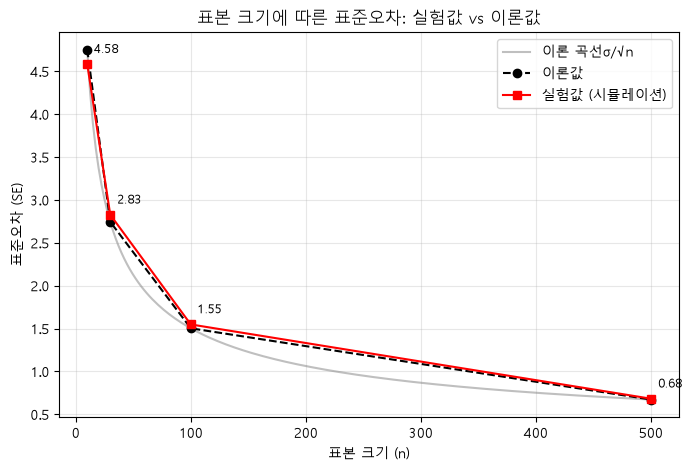

In [81]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.

# 여기에 코드를 작성해주세요.

# 매끄러운 이론 곡선 (σ/√n)
n_range = np.linspace(10, 500, 200)
theory_curve = sigma / np.sqrt(n_range)

plt.figure(figsize=(8, 5))
plt.plot(n_range, theory_curve, color='gray', alpha=0.5, label='이론 곡선σ/√n')
plt.plot(df_se['표본 크기'], df_se['이론적 표준오차'], 'o--', color='black', label='이론값')
plt.plot(df_se['표본 크기'], df_se['실험적 표준오차'], 's-', color='red',label='실험값 (시뮬레이션)')

# 각 점에 실험값 표시
for n, se in zip(df_se['표본 크기'], df_se['실험적 표준오차']):
    plt.annotate(f'{se:.2f}', (n, se), textcoords='offset points', xytext=(5, 8), fontsize=9)

plt.title('표본 크기에 따른 표준오차: 실험값 vs 이론값')
plt.xlabel('표본 크기 (n)')
plt.ylabel('표준오차 (SE)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?

In [ ]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 1. 표본 크기가 작을수록 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?
#    → 표본 크기가 작을수록 표본 평균의 분포는 넓게 퍼져 있다.
#      (모집단이 정규분포라 모양은 종 모양이고, 폭만 넓다.)

# 2. 표본 크기가 커질수록 평균 분포는 어떻게 변하나요?
#    → 중심(모평균 100)은 그대로이고, 분포의 폭이 좁아진다.
#      즉, 표본 평균이 모평균 근처에 더 촘촘히 모인다.

# 3. 실험값과 이론값은 얼마나 비슷한가요?
#    → 모든 표본 크기에서 실험값과 이론값(σ/√n)이 거의 일치했다.
#      n이 커질수록 표준오차 자체가 작아져 절대 차이도 줄어들지만,
#      오차율(%)은 n과 상관없이 몇 % 수준으로 비슷했다.
#      이 차이는 반복 횟수(1000번)가 유한해서 생기는 시뮬레이션 오차이며,
#      반복 횟수를 늘리면 더 줄어든다.

# 4. 왜 표본 크기가 커질수록 표준오차는 작아질까요?
#    → 독립인 값 n개를 평균 내면 분산이 σ²/n이 되어, 표준편차(표준오차)는 σ/√n이 된다.
#      값이 많을수록 큰 값과 작은 값이 서로 상쇄되어 평균이 모평균에서 덜 흔들리기 때문이다.
#      단, √n에 반비례하므로 표준오차를 절반으로 줄이려면 표본 크기를 4배로 늘려야 한다.

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

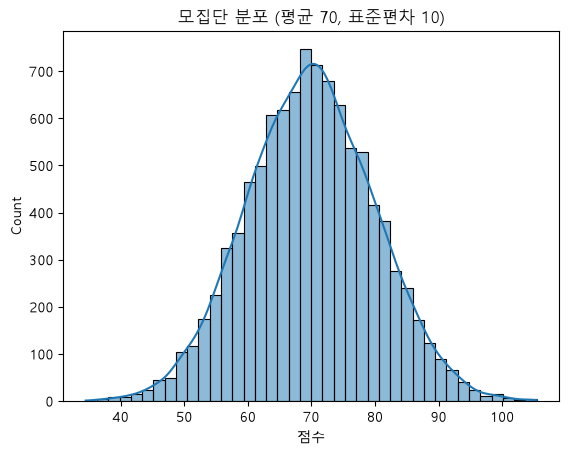

In [91]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [92]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.

n = 30
sample = np.random.choice(population, size=n, replace=False)

x_bar = sample.mean()              # 표본 평균
s = sample.std(ddof=1)             # 표본 표준편차 (n-1로 나눔)
se = s / np.sqrt(n)                # 표준오차 = s / √n

print(f'표본 크기      : {n}')
print(f'표본 평균      : {x_bar:.3f}')
print(f'표본 표준편차  : {s:.3f}')
print(f'표준오차 (SE)  : {se:.3f}')
print(f'(참고) 모집단 평균: {population.mean():.3f}, 모집단 표준편차: {population.std():.3f}')

표본 크기      : 30
표본 평균      : 67.604
표본 표준편차  : 11.078
표준오차 (SE)  : 2.023
(참고) 모집단 평균: 69.904, 모집단 표준편차: 10.005


In [93]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

from scipy import stats

sigma_pop = population.std()                     # 모집단 표준편차 (알고있다고 가정, 약 10)
se_z = sigma_pop / np.sqrt(n)                    # σ를 아는 경우의 표준오차 = σ / √n

z = stats.norm.ppf(0.975)                        # 95% → 양쪽 2.5%씩 → z ≈ 1.96
margin_z = z * se_z                              # 오차범위

ci_z = (x_bar - margin_z, x_bar + margin_z)

print(f'z 임계값     : {z:.3f}')
print(f'표준오차     : {se_z:.3f}')
print(f'오차범위     : ±{margin_z:.3f}')
print(f'95% 신뢰구간 : ({ci_z[0]:.3f}, {ci_z[1]:.3f})')
print(f'구간 폭      : {ci_z[1] - ci_z[0]:.3f}')

# (참고) scipy 한 줄로도 계산 가능
print(stats.norm.interval(0.95, loc=x_bar, scale=se_z))

z 임계값     : 1.960
표준오차     : 1.827
오차범위     : ±3.580
95% 신뢰구간 : (64.024, 71.184)
구간 폭      : 7.160
(np.float64(64.02364114521298), np.float64(71.18406567687443))


In [94]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

df_t = n - 1                                     # 자유도 = n - 1 = 29
t = stats.t.ppf(0.975, df=df_t)                  # 95% → 양쪽 2.5%씩 → t ≈ 2.045
margin_t = t * se                                # 오차범위 (se = s/√n, Q1에서 계산)

ci_t = (x_bar - margin_t, x_bar + margin_t)

print(f'자유도       : {df_t}')
print(f't 임계값     : {t:.3f}  (z 임계값 {z:.3f})')
print(f'표준오차     : {se:.3f}')
print(f'오차범위     : ±{margin_t:.3f}')
print(f'95% 신뢰구간 : ({ci_t[0]:.3f}, {ci_t[1]:.3f})')
print(f'구간 폭      : {ci_t[1] - ci_t[0]:.3f}')

# (참고) scipy 한 줄로도 계산 가능
print(stats.t.interval(0.95, df=df_t, loc=x_bar, scale=se))

# z vs t 비교
print(f'\n[비교] z 구간 폭: {ci_z[1] - ci_z[0]:.3f} / t 구간 폭: {ci_t[1]
- ci_t[0]:.3f}')

자유도       : 29
t 임계값     : 2.045  (z 임계값 1.960)
표준오차     : 2.023
오차범위     : ±4.137
95% 신뢰구간 : (63.467, 71.740)
구간 폭      : 8.273
(np.float64(63.467245585351854), np.float64(71.74046123673554))

[비교] z 구간 폭: 7.160 / t 구간 폭: 8.273


,신뢰수준,분포,임계값,하한,상한,구간 폭
0,90%,z,1.645,64.599,70.608,6.009
1,90%,t,1.699,64.167,71.040,6.873
2,95%,z,1.960,64.024,71.184,7.160
3,95%,t,2.045,63.467,71.740,8.273
4,99%,z,2.576,62.899,72.309,9.410
5,99%,t,2.756,62.029,73.179,11.150


신뢰수준,90%,95%,99%
분포,,,
t,6.873,8.273,11.15
z,6.009,7.160,9.41


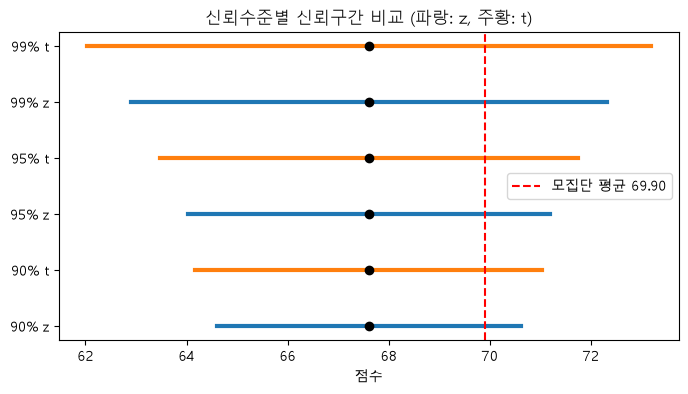

In [95]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.

conf_levels = [0.90, 0.95, 0.99]
rows = []

for cl in conf_levels:
    alpha = 1 - cl
    q = 1 - alpha / 2                                # 양쪽 꼬리 → 위쪽 임계 확률 (90%→0.95, 99%→0.995)

    # z-분포: σ / √n
    z_crit = stats.norm.ppf(q)
    z_lo, z_hi = x_bar - z_crit * se_z, x_bar + z_crit * se_z

    # t-분포: s / √n, 자유도 n-1
    t_crit = stats.t.ppf(q, df=n - 1)
    t_lo, t_hi = x_bar - t_crit * se, x_bar + t_crit * se

    rows.append({'신뢰수준': f'{int(cl*100)}%', '분포': 'z', '임계값': z_crit,
                 '하한': z_lo, '상한': z_hi, '구간 폭': z_hi - z_lo})
    rows.append({'신뢰수준': f'{int(cl*100)}%', '분포': 't', '임계값': t_crit,
                 '하한': t_lo, '상한': t_hi, '구간 폭': t_hi - t_lo})

df_ci = pd.DataFrame(rows)
display(df_ci.round(3))

# 구간 폭 비교 (가로 표)
display(df_ci.pivot(index='분포', columns='신뢰수준', values='구간 폭').round(3))

# 시각화: 신뢰수준별 신뢰구간 (z / t)
fig, ax = plt.subplots(figsize=(8, 4))
for i, r in df_ci.iterrows():
    color = 'tab:blue' if r['분포'] == 'z' else 'tab:orange'
    ax.plot([r['하한'], r['상한']], [i, i], color=color, linewidth=3)
    ax.plot(x_bar, i, 'o', color='black')
ax.axvline(population.mean(), color='red', linestyle='--', label=f'모집단 평균 {population.mean():.2f}')
ax.set_yticks(range(len(df_ci)))
ax.set_yticklabels(df_ci['신뢰수준'] + ' ' + df_ci['분포'])
ax.set_xlabel('점수')
ax.set_title('신뢰수준별 신뢰구간 비교 (파랑: z, 주황: t)')
ax.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?

In [ ]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 1. z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?
#    → z-분포는 모집단 표준편차(σ)를 알 때, t-분포는 σ를 모르고 표본 표준편차(s)로 추정할 때 쓴다.
#      t-분포는 z-분포보다 꼬리가 두꺼워 임계값이 더 크다(n=30, 95%: z 1.96, t 2.045, 약 4% 차이).
#      그래서 보통 t 구간이 조금 더 넓다. 다만 자유도(n-1)가 커질수록 t-분포는 z-분포에 가까워져
#      두 구간의 차이도 줄어든다.

# 2. 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?
#    → 신뢰수준이 높아질수록 구간이 넓어진다(90% < 95% < 99%).
#      표본을 반복해서 뽑아 구간을 만들 때, 모평균을 포함하는 구간의 비율이 더 높아야 하므로
#      임계값이 커지고(z 기준 1.645 → 1.96 → 2.576), 그만큼 구간도 넓어진다.

# 3. 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?
#    → 경우에 따라 다르다. 구간이 넓으면, 표본을 반복해서 뽑을 때 각 표본으로 만든 신뢰구간이
#      모평균을 포함할 확률은 높아지지만, 정보로서의 정밀도는 떨어진다.
#      예를 들어 '대한민국 국민의 키는 99.999% 신뢰수준에서 100cm~250cm'라는 정보는 거의 틀리지 않지만
#      쓸모가 없다. 즉 신뢰도와 정밀도는 트레이드오프 관계이다.
#      신뢰도를 낮추지 않고 구간을 좁히려면 표본 크기를 늘리면 된다(SE = σ/√n).

# 4. 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?
#    → 신뢰구간은 조사 결과를 얼마나 믿을 수 있는지 보여주는 잣대이며, 다음처럼 활용할 수 있다
#      - 목표치 비교: 구간의 하한이 목표 점수보다 높으면 '목표 달성'이라고 보수적으로 판단할 수 있다.
#      - 그룹 비교: 캠페인 전후나 고객층별 신뢰구간이 겹치지 않으면 실제 차이가 있다고 볼 근거가 된다.
#      - 조사 설계: 구간이 너무 넓어 의사결정에 쓰기 어렵다면, 다음 조사에서표본 크기를 늘린다.

# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

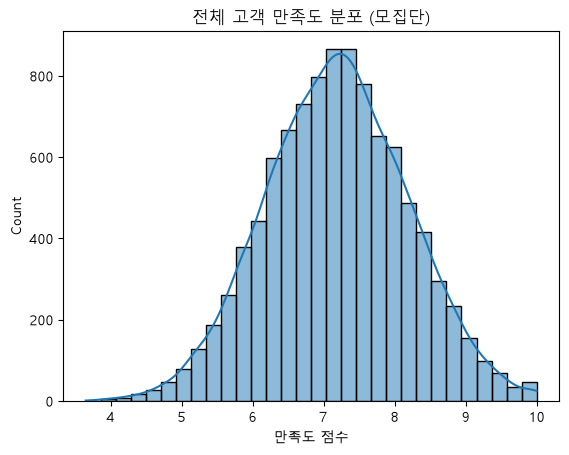

In [43]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [45]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요.

n_40 = 40
sample_40 = np.random.choice(population, size=n_40, replace=False)

mean_40 = sample_40.mean()            # 표본 평균
std_40 = sample_40.std(ddof=1)        # 표본 표준편차 (n-1로 나눔)

print(f'표본 크기     : {n_40}')
print(f'표본 평균     : {mean_40:.3f}')
print(f'표본 표준편차 : {std_40:.3f}')
print(f'(참고) 모집단 평균: {population.mean():.3f}, 모집단 표준편차: {population.std():.3f}')

표본 크기     : 40
표본 평균     : 7.144
표본 표준편차 : 1.099
(참고) 모집단 평균: 7.190, 모집단 표준편차: 0.998


In [47]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
# 여기에 코드를 작성해주세요.

from scipy import stats

se_40 = std_40 / np.sqrt(n_40)                       # 표준오차 = s / √n
t_40 = stats.t.ppf(0.975, df=n_40 - 1)               # 자유도 39, 95% → t ≈ 2.023
margin_40 = t_40 * se_40                             # 오차범위

ci_40 = (mean_40 - margin_40, mean_40 + margin_40)

print(f'표준오차 (SE) : {se_40:.3f}')
print(f't 임계값      : {t_40:.3f}  (자유도 {n_40 - 1})')
print(f'오차범위      : ±{margin_40:.3f}')
print(f'95% 신뢰구간  : ({ci_40[0]:.3f}, {ci_40[1]:.3f})')
print(f'구간 폭       : {ci_40[1] - ci_40[0]:.3f}')

# 모집단 평균이 신뢰구간 안에 들어가는지 확인
pop_mean = population.mean()
print(f'\n모집단 평균 {pop_mean:.3f} → 신뢰구간 포함 여부: {ci_40[0] <= pop_mean <= ci_40[1]}')

표준오차 (SE) : 0.174
t 임계값      : 2.023  (자유도 39)
오차범위      : ±0.351
95% 신뢰구간  : (6.793, 7.496)
구간 폭       : 0.703

모집단 평균 7.190 → 신뢰구간 포함 여부: True


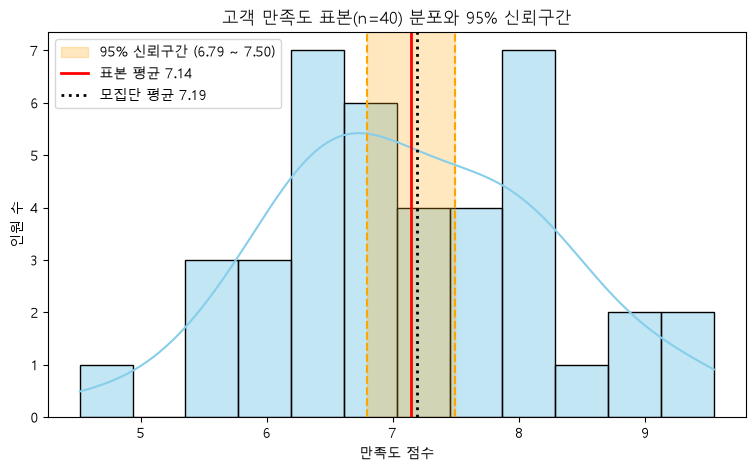

In [49]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
#  여기에 코드를 작성해주세요.

plt.figure(figsize=(9, 5))
sns.histplot(sample_40, bins=12, kde=True, color='skyblue')

# 95% 신뢰구간 영역 (음영)
plt.axvspan(ci_40[0], ci_40[1], color='orange', alpha=0.25,
            label=f'95% 신뢰구간 ({ci_40[0]:.2f} ~ {ci_40[1]:.2f})')
plt.axvline(ci_40[0], color='orange', linestyle='--')
plt.axvline(ci_40[1], color='orange', linestyle='--')

# 표본 평균 / 모집단 평균
plt.axvline(mean_40, color='red', linewidth=2, label=f'표본 평균 {mean_40:.2f}')
plt.axvline(population.mean(), color='black', linestyle=':', linewidth=2,
            label=f'모집단 평균 {population.mean():.2f}')

plt.title(f'고객 만족도 표본(n={n_40}) 분포와 95% 신뢰구간')
plt.xlabel('만족도 점수')
plt.ylabel('인원 수')
plt.legend()
plt.show()

In [ ]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?
# 여기에 의견을 작성해주세요.

# → 표본 40명으로 구한 95% 신뢰구간은 약 (6.79) ~ (7.50)점으로, 고객 만족도의 평균은 7점 안팎이다.
#   10점 만점 기준으로 대체로 양호한 수준이지만, '높다'고 판단하려면 목표치나
#   비교 대상(이전 조사, 경쟁사, 업계 평균)과 함께 보아야 한다.
#   이 신뢰구간은 마케팅 전략을 세우는 기초 통계 자료로 다음과 같이 활용할 수 있다.
#
#   - 하한이 목표치(예: 7점)보다 높으면: 만족도가 목표를 넘는다고 보수적으로 판단할 수 있으므로,
#     만족도를 강점으로 내세운 홍보나 기존 고객 추천(리퍼럴) 이벤트를 진행한다.
#   - 구간이 목표치에 걸쳐 있으면: 아직 확신할 수 없으므로, 표본을 늘려 추가 조사하거나
#     낮은 점수를 준 고객의 불만 요인을 먼저 파악한다.
#   - 상한조차 목표치보다 낮으면: 홍보보다 서비스 개선을 우선한다.
#
#   다만 신뢰구간이 너무 넓다면 표본 크기를 늘려야 한다는 신호이다.
#   구간이 넓으면 정밀도가 떨어져 위 판단의 근거로 쓰기 어렵기 때문이다.

**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?

- 이 구간은 전체 모집단 평균을 포함하고 있나요?

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?

In [ ]:
# [문제 5] 데이터를 어떻게 읽을까요?

# 1. 신뢰구간은 몇 점에서 몇 점 사이인가요?
#    → 95% 신뢰구간은 약 (하한) ~ (상한)점이다.

# 2. 이 구간은 전체 모집단 평균을 포함하고 있나요?
#    → 모집단 평균(약 7.2)을 포함한다. (포함 여부: True)

# 3. 고객 만족도가 충분히 높다고 말할 수 있을까요?
#    → 10점 만점에 7점 안팎으로 양호한 편이지만, '충분히 높다'고 하려면
#      목표치나 비교 대상(이전 조사, 경쟁사)과 비교해야 한다.

# 4. 신뢰구간이 너무 넓게 나왔다면, 그 이유와 개선 방법은?
#    → 표본 크기가 작거나 응답의 편차가 크면 표준오차(s/√n)가 커져 구간이 넓어진다.
#      표본 크기를 늘리면 구간을 좁힐 수 있다.